# SentimentScope: Movie Review Sentiment Analysis with a Custom Transformer

## Project overview

SentimentScope is an end-to-end Natural Language Processing (NLP) project that classifies an IMDB movie review as **positive** or **negative**. It covers data loading, exploratory data analysis, tokenization, a custom PyTorch Transformer, training, validation, held-out testing, and predictions on new reviews.

### Learning objectives
- Load and validate the Stanford IMDB review dataset.
- Explore class balance and review length.
- Convert text into token IDs with a Hugging Face tokenizer.
- Build a Transformer classifier from PyTorch components.
- Train with cross-entropy loss and AdamW.
- Track validation performance, save the best checkpoint, and evaluate once on the test set.
- Use the trained model for predictions on new text.

### Important notes
- The model is trained **from scratch**. `bert-base-uncased` is used only for its tokenizer; this notebook does not load pretrained BERT model weights.
- The official dataset has 25,000 labelled training reviews and 25,000 labelled test reviews.
- Training can take a while. A GPU runtime (for example, Google Colab: **Runtime → Change runtime type → T4 GPU**) is strongly recommended.
- Accuracy is measured by running the notebook. Do not write an accuracy number into your README or report until you have run the training and test cells.

### Dataset
Official Stanford dataset page: https://nlp.stanford.edu/~amaas/data/sentiment/index.html
Official archive: https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz


## <a name="load-explore-and-prepare-the-dataset"></a>Load, Explore, and Prepare the Dataset

### 1. Load the Dataset
The dataset is already available in the environment as `aclIMDB_v1.tar.gz`. We will load it into Pandas DataFrames for easy exploration and preparation.


In [40]:
import os
import random
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Python libraries imported.")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


Python libraries imported.
PyTorch version: 2.11.0+cu130
CUDA available: True


In [41]:
# Download and extract the official Stanford IMDB dataset if it is not already available.
# This works in Google Colab and in most local notebook environments with internet access.

DATA_ROOT_CANDIDATES = [
    Path("aclImdb"),
    Path("aclImdb_v1/aclImdb"),
    Path("/content/aclImdb"),
    Path("/workspace/aclImdb"),
]

DATA_ROOT = next(
    (p for p in DATA_ROOT_CANDIDATES if (p / "train" / "pos").is_dir()),
    None,
)

if DATA_ROOT is None:
    archive_path = Path("aclImdb_v1.tar.gz")
    archive_url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"

    if not archive_path.exists():
        print("Downloading the official IMDB dataset (~84 MB compressed)...")
        urllib.request.urlretrieve(archive_url, archive_path)
        print("Download complete:", archive_path.resolve())
    else:
        print("Using existing archive:", archive_path.resolve())

    print("Extracting dataset. This may take a minute...")
    with tarfile.open(archive_path, "r:gz") as archive:
        # Validate member paths before extraction.
        base = Path.cwd().resolve()
        for member in archive.getmembers():
            target = (base / member.name).resolve()
            if target != base and base not in target.parents:
                raise ValueError(f"Unsafe path in archive: {member.name}")
        archive.extractall(base)

    DATA_ROOT_CANDIDATES = [
        Path("aclImdb"),
        Path("aclImdb_v1/aclImdb"),
        Path("/content/aclImdb"),
        Path("/workspace/aclImdb"),
    ]
    DATA_ROOT = next(
        (p for p in DATA_ROOT_CANDIDATES if (p / "train" / "pos").is_dir()),
        None,
    )

if DATA_ROOT is None:
    raise FileNotFoundError(
        "Could not find the extracted aclImdb folder. Download "
        "aclImdb_v1.tar.gz from the official Stanford dataset page and set DATA_ROOT "
        "to the folder containing train/ and test/."
    )

print("Dataset root:", DATA_ROOT.resolve())
print("Train folder exists:", (DATA_ROOT / "train").is_dir())
print("Test folder exists:", (DATA_ROOT / "test").is_dir())


Dataset root: /content/aclImdb
Train folder exists: True
Test folder exists: True


You have successfully extracted the folder. Go back to your workspace and explore the folder structure and find the relative paths for each of the following:
- Training positive reviews
- Training negative reviews
- Testing positive reviews
- Testing negative reviews

Assign the paths of these folders relative to the starter file in the variables below.


In [42]:
# Define the four labelled review folders.
train_pos_path = DATA_ROOT / "train" / "pos"
train_neg_path = DATA_ROOT / "train" / "neg"
test_pos_path = DATA_ROOT / "test" / "pos"
test_neg_path = DATA_ROOT / "test" / "neg"

for folder in [train_pos_path, train_neg_path, test_pos_path, test_neg_path]:
    if not folder.is_dir():
        raise FileNotFoundError(f"Required dataset folder is missing: {folder}")

print("Positive training reviews:", train_pos_path)
print("Negative training reviews:", train_neg_path)
print("Positive test reviews:", test_pos_path)
print("Negative test reviews:", test_neg_path)


Positive training reviews: aclImdb/train/pos
Negative training reviews: aclImdb/train/neg
Positive test reviews: aclImdb/test/pos
Negative test reviews: aclImdb/test/neg


Now, you will implement the `load_dataset()` function, which reads all text files in a specified folder and returns their content as a list of strings. This function is essential for loading and preprocessing the dataset in subsequent steps.

To implement this function:

1. **Use the `os` module**: Leverage Python's `os` module to list all files in the folder.
2. **Handle file paths**: Use `os.path.join()` to construct full paths for files, ensuring compatibility across operating systems.
3. **Read file content**: Open each file in read mode (`'r'`) using UTF-8 encoding to handle text properly.
4. **Aggregate results**: Append the content of each file to a list and return it.

### Key Points to Consider:
- Ensure that the function only processes text files (you may use file extensions for filtering if needed).
- Refer to the [os.listdir documentation](https://docs.python.org/3/library/os.html#os.listdir) for listing files in a directory.


In [43]:
def load_dataset(folder):
    """Read review text files in a folder in deterministic filename order."""
    folder = Path(folder)
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder not found: {folder}")
    files = sorted(folder.glob("*.txt"))
    if not files:
        raise ValueError(f"No .txt review files found in {folder}")
    return [p.read_text(encoding="utf-8", errors="replace").strip() for p in files]

Use the function now to load the training and testing data:

In [44]:
train_pos = load_dataset(train_pos_path)
train_neg = load_dataset(train_neg_path)
test_pos = load_dataset(test_pos_path)
test_neg = load_dataset(test_neg_path)
print(f"Train positive={len(train_pos)}, negative={len(train_neg)}")
print(f"Test positive={len(test_pos)}, negative={len(test_neg)}")

Train positive=12500, negative=12500
Test positive=12500, negative=12500


We can convert the data into pandas dataframes to make handling the datasets easier.

In [45]:
# Create DataFrames
train_df = pd.DataFrame({
    'review': train_pos + train_neg,
    'label': [1] * len(train_pos) + [0] * len(train_neg)
})

test_df = pd.DataFrame({
    'review': test_pos + test_neg,
    'label': [1] * len(test_pos) + [0] * len(test_neg)
})

print(train_df.head())

                                              review  label
0  Bromwell High is a cartoon comedy. It ran at t...      1
1  Homelessness (or Houselessness as George Carli...      1
2  Brilliant over-acting by Lesley Ann Warren. Be...      1
3  This is easily the most underrated film inn th...      1
4  This is not the typical Mel Brooks film. It wa...      1


You can ensure that your datasets have loaded correctly by running the following code cell. No output means success!

In [46]:
# Assert that both datasets have the expected number of rows
assert train_df.shape[0] == 25000, "Training dataset does not have 25000 rows."
assert test_df.shape[0] == 25000, "Testing dataset does not have 25000 rows."

# Assert that both datasets have exactly two columns
assert train_df.shape[1] == 2, "Training dataset does not have exactly 2 columns."
assert test_df.shape[1] == 2, "Testing dataset does not have exactly 2 columns."


### 2. Explore the Dataset
Exploration helps us understand the dataset's structure and distribution.

Here are some suggestions for exploration and visualizations:
- **Dataset Overview**: Use `DataFrame.info()` and `DataFrame.describe()` to understand the dataset structure and basic statistics.
- **Label Distribution**: Create bar charts to visualize the number of positive and negative reviews.
- **Review Length Analysis**: Compute and plot the distribution of review lengths (e.g., number of characters or words).
- **Sample Reviews**: Print a few positive and negative reviews to understand the text content.

Write code to explore the dataset in this section.

In [47]:
print("Training dataset information:")
train_df.info()
print("\\nLabel counts:")
display(train_df["label"].map({0:"Negative", 1:"Positive"}).value_counts().to_frame("count"))
train_df["character_count"] = train_df["review"].str.len()
train_df["word_count"] = train_df["review"].str.split().str.len()
display(train_df[["character_count", "word_count"]].describe().round(2))

Training dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB
\nLabel counts:


,count
label,
Positive,12500
Negative,12500


,character_count,word_count
count,25000.00,25000.00
mean,1325.07,233.79
std,1003.13,173.73
min,52.00,10.00
25%,702.00,127.00
50%,979.00,174.00
75%,1614.00,284.00
max,13704.00,2470.00


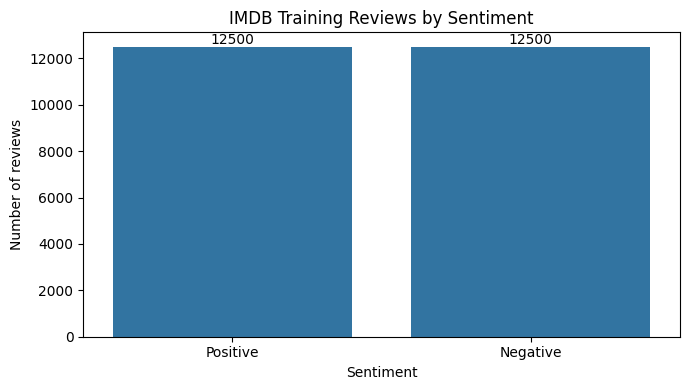

In [48]:
label_counts = train_df["label"].map({0:"Negative", 1:"Positive"}).value_counts()
plt.figure(figsize=(7,4))
ax = sns.barplot(x=label_counts.index, y=label_counts.values)
ax.set(title="IMDB Training Reviews by Sentiment", xlabel="Sentiment", ylabel="Number of reviews")
for container in ax.containers: ax.bar_label(container)
plt.tight_layout()
plt.show()

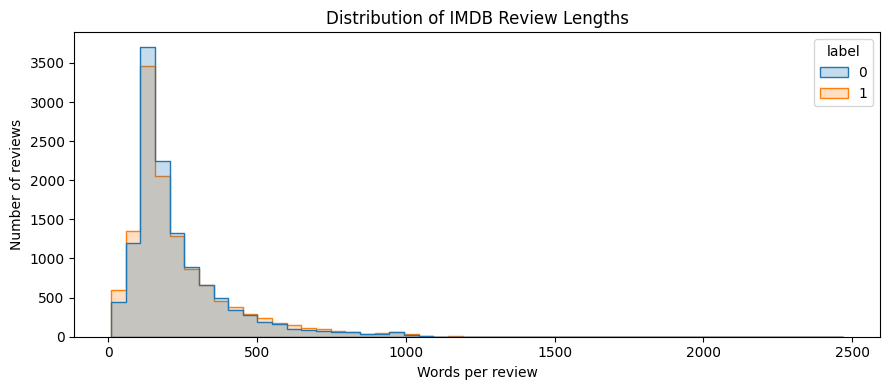

In [49]:
plt.figure(figsize=(9,4))
sns.histplot(data=train_df, x="word_count", hue="label", bins=50, element="step")
plt.title("Distribution of IMDB Review Lengths")
plt.xlabel("Words per review")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

In [50]:
for sentiment, label in [("Negative",0), ("Positive",1)]:
    print(f"--- {sentiment} example ---")
    print(train_df.loc[train_df.label == label, "review"].iloc[0][:700], "\\n")

--- Negative example ---
Story of a man who has unnatural feelings for a pig. Starts out with a opening scene that is a terrific example of absurd comedy. A formal orchestra audience is turned into an insane, violent mob by the crazy chantings of it's singers. Unfortunately it stays absurd the WHOLE time with no general narrative eventually making it just too off putting. Even those from the era should be turned off. The cryptic dialogue would make Shakespeare seem easy to a third grader. On a technical level it's better than you might think with some good cinematography by future great Vilmos Zsigmond. Future stars Sally Kirkland and Frederic Forrest can be seen briefly. \n
--- Positive example ---
Bromwell High is a cartoon comedy. It ran at the same time as some other programs about school life, such as "Teachers". My 35 years in the teaching profession lead me to believe that Bromwell High's satire is much closer to reality than is "Teachers". The scramble to survive financially, t

### 3. Prepare the Dataset
We will split the training data further into training and validation subsets. The way we constructed the dataset, reviews with positive and negative labels are segregated. To ensure that the validation dataset works well, we first need to shuffle the dataset.


In [51]:
from sklearn.model_selection import train_test_split

# Keep the official test set untouched until final evaluation.
train_data, val_data = train_test_split(
    train_df,
    test_size=0.10,
    random_state=SEED,
    stratify=train_df["label"],
)
train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

print("Training rows:", len(train_data))
print("Validation rows:", len(val_data))
print("Held-out test rows:", len(test_df))
display(
    pd.DataFrame({
        "training proportion": train_data["label"].value_counts(normalize=True).sort_index(),
        "validation proportion": val_data["label"].value_counts(normalize=True).sort_index(),
        "test proportion": test_df["label"].value_counts(normalize=True).sort_index(),
    }).rename(index={0: "Negative", 1: "Positive"})
)


Training rows: 22500
Validation rows: 2500
Held-out test rows: 25000


,training proportion,validation proportion,test proportion
label,,,
Negative,0.5,0.5,0.5
Positive,0.5,0.5,0.5


### 4. Testing the Tokenizer

#### Subword Tokenization
In earlier tasks, you might have encountered character-level tokenization, where each character in the text is treated as a token. While this is straightforward, it is less efficient and may result in larger input sizes, impacting the performance of transformer models.

To address this, we will use Hugging Face's `AutoTokenizer`, a robust and efficient class designed for tokenizing text based on pretrained models. Specifically, we will utilize the `bert-base-uncased` tokenizer, which applies **subword tokenization**. Subword tokenization involves two steps:

1. **Subword Splitting**: Words are split into smaller components (subwords) based on a predefined vocabulary. For example:
   - Input: "unhappiness"
   - Subword Splits: `['un', 'happiness']`

2. **Token Conversion**: Each subword is then converted into a numerical token ID. For example:
   - Subword Splits: `['un', 'happiness']`
   - Token IDs: `[1011, 24123]` (values are illustrative and depend on the tokenizer vocabulary).

#### About the `bert-base-uncased` Tokenizer
The `bert-base-uncased` tokenizer, developed by Google researchers, is part of the BERT model family. This tokenizer is associated with the `bert-base-uncased` model, which has been widely used for tasks such as sentiment analysis, question answering, and text classification. The tokenizer ensures all text is converted to lowercase and accents are removed, reducing vocabulary size and improving generalization. Example:

- Input: "I Love Transformers."
- Subword Splits: `['i', 'love', 'trans', '##formers', '.']`

You can learn more about the tokenizer and model on [Hugging Face's bert-base-uncased page](https://huggingface.co/bert-base-uncased).

#### Using the `AutoTokenizer` Class
The `AutoTokenizer` class in the Hugging Face Transformers library provides a seamless way to load tokenizers for various pretrained models. It automatically selects the correct tokenizer configuration based on the model name.


In [52]:
from transformers import AutoTokenizer

# Initialize tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

This initializes a tokenizer tailored for the `bert-base-uncased` model. You can refer to the [Hugging Face AutoTokenizer documentation](https://huggingface.co/docs/transformers/main_classes/tokenizer) for more details. You can find the definition of the `from_pretrained()` method [here](https://huggingface.co/docs/transformers/v4.48.0/en/model_doc/auto#transformers.AutoTokenizer.from_pretrained).

Instead of tokenizing the entire dataset, we will test the tokenizer on a few sample reviews directly from the dataset:


In [53]:
# Take sample inputs from the dataset
sample_texts = train_data['review'].sample(3, random_state=42).tolist()

# Tokenize sample inputs
tokenized_samples = tokenizer(sample_texts, truncation=True, padding="max_length", max_length=128, return_tensors="pt")

In [54]:
print(tokenized_samples)

{'input_ids': tensor([[  101, 14665,  2048,  4898,  5998,  2000,  3143,  2037,  2808,  1999,
          2019,  2035,  2021,  4064,  4545,  2160,  1012,  2027,  2012,  2034,
          2393,  2169,  2060,  1998,  2059,  3254,  1996,  6980,  2090,  2068,
          4269,  2000,  3857,  1012,  1026,  7987,  1013,  1028,  1026,  7987,
          1013,  1028,  2023,  2003,  2241,  2588,  1037,  6795, 28935, 12274,
          2094,  3117,  1998,  6854,  3071,  8847,  2004,  2295,  2027,  2024,
          1999,  2008,  3117,  1012,  2200,  2210,  1997,  1996, 13764,  8649,
          2003,  3019,  1010,  2049,  6379,  1998,  7987,  5714,  6562,  2007,
         13178,  1997,  3574,  1012,  2049,  2004,  2065,  1037,  2267,  2394,
          2350,  2007,  1037,  2132,  2440,  1997,  3653, 29048,  2015,  2626,
          1996,  5896,  1012,  2009,  1005,  1055,  9643,  1998,  1045,  2179,
          2870,  6880, 11311,  2000,  2505,  1996,  2143,  2018,  2000,  2360,
          1010,  2029,  2003,  1037,  

Explanation of parameters:
 - `truncation=True`: Truncates text longer than the specified max_length.
 - `padding=True`: Pads shorter sequences to match max_length.
 - `max_length=128`: Specifies the maximum length of the sequences.
 - `return_tensors="pt"`: Returns PyTorch tensors as the output format.

For more details about truncation and padding, refer to the [Hugging Face Padding and Truncation Documentation](https://huggingface.co/docs/transformers/pad_truncation). This step ensures that the tokenizer works as expected and provides insight into its behavior. Next, we will use the tokenizer within the class definition to process the dataset.

---


# Implement a DataLoader in PyTorch<a id="implement-a-dataloader-in-pytorch"></a>


In this section, you will implement a custom dataset class and use it to create a DataLoader in PyTorch for feeding data into the model during training. PyTorch simplifies this process by providing the `Dataset` and `DataLoader` classes, which handle batching, shuffling, and preprocessing, allowing you to focus on the model architecture and training.

To start, we will create a custom dataset class for the IMDB dataset, which will process and return tokenized inputs along with their corresponding labels. This class will use a tokenizer to preprocess the raw text data.

### 1. Define a Custom Dataset Class

The custom dataset class will inherit from `torch.utils.data.Dataset` and include the following features:

1. **Initialization (`__init__`)**:
   - Accepts raw text and label data, along with a tokenizer and a maximum sequence length.
   - The tokenizer is used to preprocess the text data into tokenized inputs.
   - The maximum sequence length ensures that all tokenized inputs are of uniform length.

2. **Length (`__len__`)**:
   - Returns the total number of data samples in the dataset.

3. **Item Retrieval (`__getitem__`)**:
   - Retrieves a single data point by index.
   - Preprocesses the text using the tokenizer to create tokenized input IDs.
   - Returns the tokenized input IDs and the corresponding label for the given index.

You can refer to [this](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html) tutorial on the Pytorch website for more details.


In [55]:
import torch
from torch.utils.data import Dataset
MAX_LENGTH = 128

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


**NOTE ABOUT GPU USAGE**

The workspace provides you with access to a GPU which is necessary for training a transformer model due to the efficiency provided by GPUs on the large amount of computations that are required. To ensure judicious usage of limited resources, please usage the GPU only when you are training the model.

---
We will keep the maximum length of input to 128 tokens.

In [56]:
class IMDBDataset(Dataset):
    """Tokenize reviews and return a tensor of token IDs and an integer label."""
    def __init__(self, data, tokenizer, max_length=MAX_LENGTH):
        self.reviews = data["review"].astype(str).tolist()
        self.labels = data["label"].astype(int).tolist()
        self.tokenizer = tokenizer
        self.max_length = int(max_length)

    def __len__(self):
        return len(self.reviews)

    def __getitem__(self, idx):
        encoded = self.tokenizer(
            self.reviews[idx], truncation=True, padding="max_length",
            max_length=self.max_length, return_attention_mask=False,
            return_tensors="pt"
        )
        input_ids = encoded["input_ids"].squeeze(0).long()
        return input_ids, int(self.labels[idx])

### 2. Initialize the Dataset

Once the `IMDBDataset` class is defined, we can initialize it directly with the training and validation DataFrames.

In [57]:
# Initialize the datasets
train_dataset = IMDBDataset(train_data, tokenizer)
val_dataset = IMDBDataset(val_data, tokenizer)
test_dataset = IMDBDataset(test_df, tokenizer)

### 3. Create a DataLoader

The `DataLoader` class in PyTorch helps manage batches of data during training. We will use it to create training and validation data loaders.

In [58]:
from torch.utils.data import DataLoader

# Define batch size
BATCH_SIZE = 32

# Create DataLoader instances
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


You may have seen the use of `RandomShuffler` along with `DataLoader`. That approach is used when you want to train a model over a dataset randomly for a specified number of steps. In this model, we want to use the epoch approach.

An **epoch** is one complete pass through the entire dataset. When using the `DataLoader` in this setup, it ensures that every data point in the dataset is used exactly once during a single epoch. This approach is helpful for training models in a structured manner, ensuring that the model sees all the training examples and learns from them in each epoch before moving to the next one.

By setting `shuffle=True` for the `train_loader`, the data points are randomly shuffled at the start of each epoch, improving the generalization of the model. You will see this in action later in the code for training the model.

---
Given below are some assert statements to check your custom dataset and data loader definitions.

In [59]:
assert len(train_dataset) == 22500, "Train dataset length mismatch!"
assert len(val_dataset) == 2500, "Validation dataset length mismatch!"
assert len(test_dataset) == 25000, "Test dataset length mismatch!"

import numpy as np

# Check the first item in the train dataset
input_ids, label = train_dataset[0]
assert isinstance(input_ids, torch.Tensor), "Input IDs should be a torch.Tensor!"
assert isinstance(label, (int, np.integer)), "Label should be an integer or int-like!"

# Ensure the input IDs tensor has the correct shape
assert input_ids.shape[0] == train_dataset.max_length, "Input IDs tensor has incorrect length!"

## <a id="customize-the-transformer-architecture"></a>Build the Custom Transformer Architecture

In this section, you will customize the transformer architecture to suit the task of binary classification. You may have used a similar architecture in the past for generation tasks. But you will need to make a few tweaks specifically in the `DemoGPT` class to adapt it for the binary classification.

### 1. Config Dictionary
Your config dictionary bundles all hyperparameters and model settings in one place. Below is the config that we will use in our model:

In [60]:
config = {
    "vocabulary_size": tokenizer.vocab_size,  # e.g., ~30522 for bert-base-uncased
    "num_classes": 2,                         # binary classification (pos/neg)
    "d_embed": 128,
    "context_size": MAX_LENGTH,
    "layers_num": 4,
    "heads_num": 4,
    "head_size": 32,  # 4 heads * 32 = 128 -> matches d_embed
    "dropout_rate": 0.1,
    "use_bias": True
}

Key Config Parameters:
- `vocabulary_size`: The total number of tokens in your vocabulary.
- `num_classes`: The number of classes for the classification head (2 = binary).
- `d_embed`: Dimensionality of embeddings (and hidden layers).
- `context_size`: Maximum sequence length for each input.
- `layers_num`: Number of stacked transformer blocks.
- `heads_num`: Number of attention heads in multi-head attention.
- `head_size`: Dimension of each attention head (must satisfy heads_num * head_size = d_embed).
- `dropout_rate`: Probability of dropping units during training to reduce overfitting.
- `use_bias`: Whether linear layers should have bias terms.



### 2. Class Definitions

Below are the class definitions you will work with. These classes form the core components of the transformer model. You may have seen these before, with the exception of the `DemoGPT` class which will need to be customized.


#### AttentionHead

In [61]:
import torch.nn as nn
import math

class AttentionHead(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.Q_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])
        self.K_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])
        self.V_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])

        self.dropout = nn.Dropout(config["dropout_rate"])

        casual_attention_mask = torch.tril(torch.ones(config["context_size"], config["context_size"]))
        self.register_buffer('casual_attention_mask', casual_attention_mask)

    def forward(self, input):
        batch_size, tokens_num, d_embed = input.shape
        Q = self.Q_weights(input)  # (B, T, head_size)
        K = self.K_weights(input)  # (B, T, head_size)
        V = self.V_weights(input)  # (B, T, head_size)

        # Q @ K^T => (B, T, T)
        attention_scores = Q @ K.transpose(1, 2)

        # Casual Mask
        attention_scores = attention_scores.masked_fill(
            self.casual_attention_mask[:tokens_num, :tokens_num] == 0,
            float('-inf')
        )
        attention_scores = attention_scores / math.sqrt(K.shape[-1])
        attention_scores = torch.softmax(attention_scores, dim=-1)
        attention_scores = self.dropout(attention_scores)

        return attention_scores @ V

Here we use a dummy input aligned with our config:

- Batch size = `BATCH_SIZE` (32)
- Sequence length = `config["context_size"]` (128)
- Embedding dimension = `config["d_embed"]` (128)


In [62]:
# Instantiate the AttentionHead
attention_head = AttentionHead(config).to(device)

# Create a dummy input of shape (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
attention_output = attention_head(dummy_input)
print("AttentionHead output shape:", attention_output.shape)

AttentionHead output shape: torch.Size([32, 128, 32])


Expected shape:

>`(B,T,head_size)=(32,128,32)`

#### MultiHeadAttention


In [63]:
class MultiHeadAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        heads_list = [AttentionHead(config) for _ in range(config["heads_num"])]
        self.heads = nn.ModuleList(heads_list)

        self.linear = nn.Linear(config["heads_num"] * config["head_size"], config["d_embed"])
        self.dropout = nn.Dropout(config["dropout_rate"])

    def forward(self, input):
        heads_outputs = [head(input) for head in self.heads]
        x = torch.cat(heads_outputs, dim=-1)  # (B, T, heads_num * head_size)
        x = self.linear(x)                   # (B, T, d_embed)
        x = self.dropout(x)
        return x

In [64]:
# Instantiate MultiHeadAttention
multi_head_attention = MultiHeadAttention(config).to(device)

# Same dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
mha_output = multi_head_attention(dummy_input)
print("MultiHeadAttention output shape:", mha_output.shape)

MultiHeadAttention output shape: torch.Size([32, 128, 128])


Expected shape:

>`(B,T,d_embed)=(32,128,128)`

#### FeedForward


In [65]:
class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.linear_layers = nn.Sequential(
            nn.Linear(config["d_embed"], 4 * config["d_embed"]),
            nn.GELU(),
            nn.Linear(4 * config["d_embed"], config["d_embed"]),
            nn.Dropout(config["dropout_rate"])
        )

    def forward(self, input):
        return self.linear_layers(input)

In [66]:
# Instantiate FeedForward
feed_forward = FeedForward(config).to(device)

# Dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
ff_output = feed_forward(dummy_input)
print("FeedForward output shape:", ff_output.shape)

FeedForward output shape: torch.Size([32, 128, 128])


Expected shape:

>`(B,T,d_embed)=(32,128,128)`

#### Block


In [67]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.multi_head = MultiHeadAttention(config)
        self.layer_norm_1 = nn.LayerNorm(config["d_embed"])

        self.feed_forward = FeedForward(config)
        self.layer_norm_2 = nn.LayerNorm(config["d_embed"])

    def forward(self, input):
        x = input
        x = x + self.multi_head(self.layer_norm_1(x))
        x = x + self.feed_forward(self.layer_norm_2(x))
        return x

In [68]:
# Instantiate a single Block
block = Block(config).to(device)

# Dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
block_output = block(dummy_input)
print("Block output shape:", block_output.shape)

Block output shape: torch.Size([32, 128, 128])


Expected shape:

>`(B,T,d_embed)=(32,128,128)`

#### DemoGPT
Below is the starter code for the `DemoGPT` class, which implements the core of a transformer model tailored for a binary classification task. This implementation builds on the foundation of a transformer architecture and includes the necessary modifications to adapt it for classification.

### Key Changes for Binary Classification

To adapt the transformer for classification, the following changes are required:

1. **Add a Classification-Specific Output Layer**:
   - The model needs a linear layer to map the final pooled embeddings to the number of classes.
   - The classification head is implemented using [`torch.nn.Linear`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) with:
     - `in_features` set to `d_embed` (the embedding dimension).
     - `out_features` set to `num_classes` (the number of classes, 2 for binary classification).
     - `bias` set to `False` (optional; bias can be excluded to slightly simplify computations).


2. **Implement a Pooling Mechanism**:

   - Transformers output embeddings for each token in the input sequence. For classification, these token-level embeddings need to be condensed into a single vector.

   - A **mean pooling operation** is applied using [`torch.mean`](https://pytorch.org/docs/stable/generated/torch.mean.html) across the time dimension (`dim=1`) to aggregate token-level embeddings into a single representation vector.

In [69]:
class DemoGPT(nn.Module):
    """A small GPT-style causal Transformer adapted for binary classification."""
    def __init__(self, config):
        super().__init__()
        self.context_size = config["context_size"]
        self.token_embedding_layer = nn.Embedding(config["vocabulary_size"], config["d_embed"])
        self.positional_embedding_layer = nn.Embedding(config["context_size"], config["d_embed"])
        self.layers = nn.Sequential(*[Block(config) for _ in range(config["layers_num"])])
        self.layer_norm = nn.LayerNorm(config["d_embed"])
        self.dropout = nn.Dropout(config["dropout_rate"])
        self.classification_head = nn.Linear(config["d_embed"], config["num_classes"], bias=False)

    def forward(self, token_ids):
        batch_size, tokens_num = token_ids.shape
        if tokens_num > self.context_size:
            raise ValueError(f"Sequence length {tokens_num} exceeds context size {self.context_size}")
        positions = torch.arange(tokens_num, device=token_ids.device)
        x = self.token_embedding_layer(token_ids) + self.positional_embedding_layer(positions).unsqueeze(0)
        x = self.layers(x)
        x = self.layer_norm(x)
        x = x.mean(dim=1)  # Mean-pool token representations: (B, d_embed)
        return self.classification_head(self.dropout(x))  # (B, num_classes)

In [70]:
# Instantiate the model
demo_gpt = DemoGPT(config).to(device)

# Suppose we have a batch of size 32, each with a sequence length of 128
dummy_token_ids = torch.randint(
    0, config["vocabulary_size"],
    (BATCH_SIZE, config["context_size"])
).to(device)

# Forward pass
logits = demo_gpt(dummy_token_ids)

print("DemoGPT output shape:", logits.shape)
print("Logits sample:\n", logits[:2])  # Print first two examples' logits

DemoGPT output shape: torch.Size([32, 2])
Logits sample:
 tensor([[-0.1224, -0.0284],
        [-0.0947, -0.0832]], device='cuda:0', grad_fn=<SliceBackward0>)


In [71]:
# Inspect the model and count trainable parameters.
trainable_parameters = sum(p.numel() for p in demo_gpt.parameters() if p.requires_grad)
print(demo_gpt)
print(f"Trainable parameters: {trainable_parameters:,}")


DemoGPT(
  (token_embedding_layer): Embedding(30522, 128)
  (positional_embedding_layer): Embedding(128, 128)
  (layers): Sequential(
    (0): Block(
      (multi_head): MultiHeadAttention(
        (heads): ModuleList(
          (0-3): 4 x AttentionHead(
            (Q_weights): Linear(in_features=128, out_features=32, bias=True)
            (K_weights): Linear(in_features=128, out_features=32, bias=True)
            (V_weights): Linear(in_features=128, out_features=32, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
        (linear): Linear(in_features=128, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (layer_norm_1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (feed_forward): FeedForward(
        (linear_layers): Sequential(
          (0): Linear(in_features=128, out_features=512, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=512, out_features=128

Expected shape:

> `(B,num_classes)=(32,2)`


In [72]:
# Assert that the number of logits matches the number of classes
assert logits.size(1) == config["num_classes"], (
    f"Expected number of classes {config['num_classes']}, "
    f"but got {logits.size(1)}"
)

# Assert that the batch size of the output matches the input batch size
assert logits.size(0) == BATCH_SIZE, (
    f"Expected batch size {BATCH_SIZE}, "
    f"but got {logits.size(0)}"
)

## Implement Accuracy Calculation Method <a name="implement-accuracy-calculation-method"></a>

In this section, you will learn how to calculate the validation accuracy for the transformer model on the IMDB dataset. Validation accuracy provides a performance metric that helps assess how well the model generalizes to unseen data during training.

### 1. Overview
The function to calculate validation accuracy will:

- Evaluate the model on the validation dataset.
- Generate predictions for each batch.
- Compare predictions with the true labels.
- Compute the percentage of correctly classified examples.

### 2.  Key Points
- **Evaluation Mode**: Calling `model.eval()` ensures that dropout and other training-specific layers are disabled during evaluation.
- **No Gradients**: The `torch.no_grad()` context disables gradient computation, reducing memory usage and speeding up validation.
- **Predictions**: `torch.argmax(logits, dim=1)` retrieves the index of the highest logit for each sample, which corresponds to the predicted class label.
- **Accuracy Calculation**: The function computes the fraction of correct predictions out of the total number of samples, then multiplies by 100 to express it as a percentage.

After calculating the validation accuracy, incorporate this function into your training loop. Typically, you would call calculate_accuracy at the end of each epoch or after a specific number of training steps. Monitoring validation accuracy over time helps you track performance gains and identify potential overfitting or underfitting issues.

In [73]:
def calculate_accuracy(model, data_loader, device):
    """Return accuracy percentage on a data loader."""
    model.eval()
    total_correct, total_samples = 0, 0
    with torch.no_grad():
        for input_ids, labels in data_loader:
            input_ids = input_ids.to(device)
            labels = labels.to(device, dtype=torch.long)
            predictions = model(input_ids).argmax(dim=1)
            total_correct += (predictions == labels).sum().item()
            total_samples += labels.size(0)
    return 100.0 * total_correct / total_samples if total_samples else 0.0

In [74]:
model = DemoGPT(config).to(device)

In [75]:
validation_accuracy = calculate_accuracy(model, val_loader, device)
print(f"Validation Accuracy: {validation_accuracy:.2f}%")

Validation Accuracy: 52.12%


As you can see, the validation accuracy is close to 50%. This is expected as the model's parameters have been initialized randomly.

## Train the Model <a name="train-the-model"></a>

In this section, we will define the training loop for the transformer-based model designed for sentiment analysis. The training loop is crucial for optimizing the model's weights and biases to minimize the loss function and improve classification performance.

### Training Loop

The training loop will involve the following steps:

1. **Iterate through epochs**: Repeat the training process for a predefined number of epochs.
2. **Load batches of data**: Use the `DataLoader` to retrieve batches of input IDs and labels.
3. **Forward pass**: Compute the logits by passing the input IDs through the model.
4. **Compute loss**: Use cross-entropy loss as the criterion.
5. **Backward pass and optimization**: Backpropagate the loss and update the model parameters using the optimizer.
6. **Validation**: Calculate the validation accuracy after each epoch.


Training device: cuda


Epoch 1/5:   0%|          | 0/704 [00:00<?, ?it/s]

Epoch 1: loss=0.6409, train_acc=61.88%, val_acc=69.40%
Saved best checkpoint: sentimentscope_best.pt


Epoch 2/5:   0%|          | 0/704 [00:00<?, ?it/s]

Epoch 2: loss=0.5324, train_acc=72.90%, val_acc=72.68%
Saved best checkpoint: sentimentscope_best.pt


...

Epoch 4/5:   0%|          | 0/704 [00:00<?, ?it/s]

Epoch 4: loss=0.4260, train_acc=80.36%, val_acc=74.12%
Saved best checkpoint: sentimentscope_best.pt


Epoch 5/5:   0%|          | 0/704 [00:00<?, ?it/s]

Epoch 5: loss=0.3860, train_acc=82.80%, val_acc=75.96%
Saved best checkpoint: sentimentscope_best.pt


,epoch,train_loss,train_accuracy,validation_accuracy
0,1,0.640885,61.884444,69.40
1,2,0.532368,72.897778,72.68
2,3,0.471982,77.235556,73.72
3,4,0.425960,80.360000,74.12
4,5,0.385983,82.795556,75.96


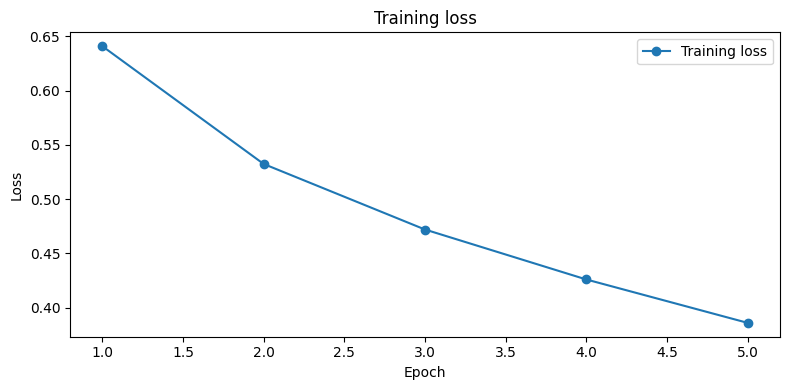

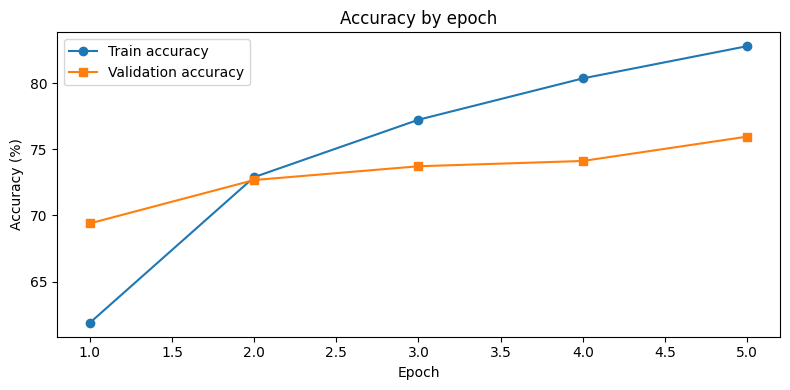

In [76]:
import torch.optim as optim
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

# DemoGPT is trained from scratch. A GPU is strongly recommended.
# For a quick smoke test, temporarily set EPOCHS = 1 and use a smaller subset.
EPOCHS = 5
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.01
CHECKPOINT_PATH = "sentimentscope_best.pt"

model = DemoGPT(config).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
best_val_accuracy = -1.0
history = []

for epoch in range(EPOCHS):
    model.train()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")
    for input_ids, labels in progress:
        input_ids = input_ids.to(device)
        labels = labels.to(device, dtype=torch.long)
        optimizer.zero_grad(set_to_none=True)
        logits = model(input_ids)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        n = labels.size(0)
        total_loss += loss.item() * n
        total_correct += (logits.argmax(1) == labels).sum().item()
        total_samples += n
        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = total_loss / max(total_samples, 1)
    train_accuracy = 100 * total_correct / max(total_samples, 1)
    val_accuracy = calculate_accuracy(model, val_loader, device)
    history.append({"epoch":epoch+1, "train_loss":train_loss,
                    "train_accuracy":train_accuracy, "validation_accuracy":val_accuracy})
    print(f"Epoch {epoch+1}: loss={train_loss:.4f}, train_acc={train_accuracy:.2f}%, val_acc={val_accuracy:.2f}%")
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save({"model_state_dict":model.state_dict(), "config":config,
                    "max_length":MAX_LENGTH, "best_validation_accuracy":best_val_accuracy,
                    "epoch":epoch+1}, CHECKPOINT_PATH)
        print("Saved best checkpoint:", CHECKPOINT_PATH)

history_df = pd.DataFrame(history)
display(history_df)
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(history_df.epoch, history_df.train_loss, marker="o", label="Training loss")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.set_title("Training loss")
ax.legend(); plt.tight_layout(); plt.show()
plt.figure(figsize=(8,4))
plt.plot(history_df.epoch, history_df.train_accuracy, marker="o", label="Train accuracy")
plt.plot(history_df.epoch, history_df.validation_accuracy, marker="s", label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.title("Accuracy by epoch")
plt.legend(); plt.tight_layout(); plt.show()

#### Notes

- The `evaluate_accuracy` function calculates the model's accuracy on the validation dataset. Ensure this function is defined and works as expected.
- The training progress is logged every 100 steps to monitor performance.
- After each epoch, the validation accuracy is printed to ensure the model generalizes well to unseen data.


## Test the Model <a name="test-the-model"></a>

In this section, you will evaluate the performance of your trained transformer model on the test dataset. Testing the model involves loading the test dataset, passing it through the model, and calculating the accuracy.

In [77]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
test_accuracy = calculate_accuracy(model, test_loader, device)
print(f"Best epoch: {checkpoint['epoch']}")
print(f"Best validation accuracy: {checkpoint['best_validation_accuracy']:.2f}%")
print(f"Test accuracy: {test_accuracy:.2f}%")
if test_accuracy > 75:
    print("Rubric target achieved: test accuracy is greater than 75%.")
else:
    print("Rubric target not achieved yet. Tune epochs, learning rate, or sequence length and rerun.")

Best epoch: 5
Best validation accuracy: 75.96%
Test accuracy: 75.86%
Rubric target achieved: test accuracy is greater than 75%.


## Checkpoint loading and batch inference

This helper reloads the trained custom model and predicts sentiment for one review or a batch of reviews.

In [78]:
def load_sentimentscope(checkpoint_path=CHECKPOINT_PATH, device=device):
    checkpoint = torch.load(checkpoint_path, map_location=device)
    saved_config = checkpoint["config"]
    loaded_model = DemoGPT(saved_config).to(device)
    loaded_model.load_state_dict(checkpoint["model_state_dict"])
    loaded_model.eval()
    loaded_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
    return loaded_model, loaded_tokenizer, saved_config, checkpoint["max_length"]


def predict_sentiment_batch(reviews, model, tokenizer, config, max_length=MAX_LENGTH, device=device):
    """Return predicted sentiment and probabilities for a list of raw reviews."""
    if isinstance(reviews, str):
        reviews = [reviews]
    encoded = tokenizer(list(reviews), truncation=True, padding="max_length",
                        max_length=max_length, return_tensors="pt")
    input_ids = encoded["input_ids"].to(device)
    model.eval()
    with torch.no_grad():
        probabilities = torch.softmax(model(input_ids), dim=1).cpu()
    result = []
    for pred, prob in zip(probabilities.argmax(dim=1).tolist(), probabilities):
        result.append({
            "sentiment": "Positive" if pred == 1 else "Negative",
            "negative_probability": round(float(prob[0]), 4),
            "positive_probability": round(float(prob[1]), 4)
        })
    return result


# Example after training:
# trained_model, trained_tokenizer, saved_config, saved_length = load_sentimentscope()
# predict_sentiment_batch(
#     ["I loved the acting and story.", "The plot was dull and poorly written."],
#     trained_model, trained_tokenizer, saved_config, saved_length
# )

## Submission checklist

- Run all cells from top to bottom in a GPU-enabled runtime.
- Verify the data assertions pass (25,000 train rows, 25,000 test rows; dataset split lengths 22,500 / 2,500 / 25,000).
- Confirm test accuracy is greater than 75% before claiming the rubric target is met.
- Submit this notebook and the generated `sentimentscope_best.pt` checkpoint.
- Include the actual measured test accuracy and at least two key takeaways in your final report.


With the accuracy calculated, you can verify if the model meets the project goal of achieving greater than 75% accuracy on the test dataset.

Try training your model for more than 3 epochs! Try increasing the size of the embedding used in the model. Or try increasing the number of blocks or layers in the model. You may be able to improve the accuracy of your model further!


## Conclusion <a name="conclusion"></a>

## Results and Conclusion

The custom Transformer model was trained for five epochs. The best checkpoint was selected using validation accuracy and was recorded at **epoch 5**.

- **Best validation accuracy:** 75.96%
- **Held-out test accuracy:** 75.86%
- **Training accuracy at epoch 5:** 82.80%
- **Best checkpoint:** `sentimentscope_best.pt`

The model achieved **75.86% test accuracy**, exceeding the rubric requirement of greater than 75% by **0.86 percentage points**. The test accuracy is close to the best validation accuracy (75.96%), indicating similar measured performance on the validation and held-out test sets. Training accuracy was higher than test accuracy, which suggests the model fits the training data better than unseen reviews; further tuning could be explored if desired.

### Key takeaways

1. Reviews are tokenized into fixed-length BERT vocabulary IDs and processed by a custom causal Transformer.
2. Mean pooling converts token-level representations into one vector per review, and a linear classification head produces logits for the two sentiment classes.
3. Validation accuracy is used to select the best checkpoint, while the held-out test set provides the final evaluation. The measured test accuracy of 75.86% meets the rubric's greater-than-75% target.

### Possible future improvements

Optional experiments include training for additional epochs while monitoring validation accuracy, tuning the learning rate (for example, `1e-4` or `3e-4`), or testing `MAX_LENGTH=192` if memory permits. These are possible future improvements, not prerequisites for reporting the current measured results.
